In [86]:
import numpy as np
import pandas as pd
import plotly.express as px

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

In [88]:
#isnull().sum() ile veride boş değerler var mı onların toplamlarına baktık
#(**.isnull().sum() / len(df)) * 100:Eksik verilerin verinin yüzde kaçı oldugunu hesapladık.
#**.duplicate().sum:Birebir aynı verinin birden fazla kez girilip girilmediğini kontrol ettik.
#**.corr(numeric_only=True): Değişkenkerin birbirleriyle doğru veya ters oranılı olup olmadıgına baktık:
    # -1 0 +1 değerleri alır:
    # +1:Mükemmel pozitif ilişki(Biri artarken diğeri de artar)
    # -1:Müjemmel negatif ilişki(Biri artarken diğeri azalır)
    # 0: Aralarında doğrusl bir ilişki yok.
#İlk olarak 7 tane tablomuz oldugundan dolayı bunları birleştirerek işlemlere başladık df_master adında.
#Ana merkezimize olist_order_dataset'i aldık tüm siparişlerin ana kayıt defteri oldugundan dolayı.
#Devamında kargo sürelerimizi hesapladık bunu da tarihleri dönüştürme ve kargo süresini hesaplauyaral yaptık.
#t-testlerde kullancağımız analizler için kargo sürelerini ilk olarak gün cinsinden hesaplayarak başladık.
#Hipotez teslerini uygulama ve sonuçlarını almak istedim. 3 istatiksel testi tek hücrede çalıştırdım.
#Anova testi ile farklı ürün kategoriliniin ortalama sipariş fiyatları arasında ki farkı test ettik.
#Ki-kare test iile ödeme yöntemleri ile yüksek memnuniyet oranı arasındaki bağımsızlıgı ilişkiyi analiz ettik.
#1. grafiğimiz lojistik başarının müşteri puanını doğrudan yükselttiğini,
#2. grafiğimiz kategoriler arası harcama tutarlarının farklılaştığını, 
#3. grafiğimizde ise kuponla ödemetercih edilen ödeme yönteminin memnuniyet oranlarıyla yüksek oranda ilişkili olduğunu doğruluyor
#Kişiler kuponla ödeme yaptıklarında kendi ceplerinden herhangi bir ücret çıkmadıgından dolayı bunu kazanç olarak görüyorlar.
#Bununla birlikte bu hissi onlara daha fazla yaşatmak ve harcama miktarlarını arttırmak için her 50-100 birimlik bir 
#harcama başına küçükten büyüğe doğru gidecek bir kupon sistemi getirerek onlara bir geri kazanım yaşatıp
#bağlılıklarını daha da arttırabiliriz.


# Veri Analiz

In [89]:
customers = pd.read_csv("olist_customers_dataset.csv")

In [90]:
order = pd.read_csv("olist_order_items_dataset.csv")

In [91]:
payment = pd.read_csv("olist_order_payments_dataset.csv")

In [92]:
reviews = pd.read_csv("olist_order_reviews_dataset.csv")

In [93]:
dataset = pd.read_csv("olist_orders_dataset.csv")

In [94]:
products = pd.read_csv("olist_products_dataset.csv")

In [95]:
sellers = pd.read_csv("olist_sellers_dataset.csv")

In [96]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [97]:
veri_setleri = {
    "customers" : customers,
    "order":order,
    "payment":payment,
    "reviews":reviews,
    "dataset":dataset,
    "products":products,
    "sellers":sellers
}

In [98]:
for isim,veriler in veri_setleri.items():
    print(f"{isim}")
    print(f"Boyut(Satır,Sütun):{veriler.shape}")
    print(f"Sütunlar:{list(veriler.columns)}")
    print(f"Baglanti:{veriler.corr(numeric_only=True)}")
    print(f"Yüzdelik: {veriler.isnull().sum() / len(veriler) * 100}")
    print("="*40)

customers
Boyut(Satır,Sütun):(99441, 5)
Sütunlar:['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
Baglanti:                          customer_zip_code_prefix
customer_zip_code_prefix                       1.0
Yüzdelik: customer_id                 0.0
customer_unique_id          0.0
customer_zip_code_prefix    0.0
customer_city               0.0
customer_state              0.0
dtype: float64
order
Boyut(Satır,Sütun):(112650, 7)
Sütunlar:['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
Baglanti:               order_item_id     price  freight_value
order_item_id       1.000000 -0.060522      -0.029380
price              -0.060522  1.000000       0.414204
freight_value      -0.029380  0.414204       1.000000
Yüzdelik: order_id               0.0
order_item_id          0.0
product_id             0.0
seller_id              0.0
shipping_limit_date    0.0
price                  0.0
freig

In [99]:
df_master = dataset.merge(customers,on="customer_id",how="left")

In [100]:
df_master=df_master.merge(order,on="order_id",how="left")
df_master=df_master.merge(payment,on="order_id",how="left")
df_master=df_master.merge(reviews,on="order_id",how="left")
df_master=df_master.merge(products,on="products_id",how="left")
df_master=df_master.merge(sellers,on="seller_id",how="left")

print("(Satır-Sütunlar:)",df_master.shape)
df_master.head()

KeyError: 'products_id'

In [ ]:
df_master

In [ ]:
tarih_sutunlari = [
    'order_purchase_timestamp', 
    'order_delivered_customer_date', 
    'order_estimated_delivery_date'
]

for col in tarih_sutunlari:
    if col in df_master.columns:
        df_master[col] = pd.to_datetime(df_master[col])

df_master['kargo_suresi_gun'] = (
    df_master['order_delivered_customer_date'] - df_master['order_purchase_timestamp']
).dt.total_seconds() / (24 * 3600)

df_master["gecikme_gun"] = (
    df_master["order_delivered_customer_date"] - df_master["order_estimated_delivery_date"]).dt.total_seconds() / (24 * 3600)

df_master['teslimat_durumu'] = df_master['gecikme_gun'].apply(
    lambda x: 'Gecikmeli' if x > 0 else 'Zamanında'
)

df_master[['kargo_suresi_gun', 'gecikme_gun']].describe().T


In [101]:
import scipy.stats as stats

print("=== 1. HIPOTEZ TESTI: Teslimat Durumu vs. Memnuniyet (t-Testi) ===")
# review_score: Müşterinin verdiği 1-5 arası puan
zamaninda = df_master[df_master['teslimat_durumu'] == 'Zamanında']['review_score'].dropna()
gecikmeli = df_master[df_master['teslimat_durumu'] == 'Gecikmeli']['review_score'].dropna()

t_stat, p_val_t = stats.ttest_ind(zamaninda, gecikmeli, alternative='greater')
print(f"Zamanında Ortalama Puan : {zamaninda.mean():.2f}")
print(f"Gecikmeli Ortalama Puan : {gecikmeli.mean():.2f}")
print(f"t-istatistiği: {t_stat:.4f}, p-değeri: {p_val_t:.4e}")
if p_val_t < 0.05:
    print("Sonuç: H0 reddedildi! Zamanında teslim edilen siparişlerin memnuniyeti anlamlı derecede daha yüksek.\n")
else:
    print("Sonuç: H0 reddedilemedi! İki grup arasında anlamlı bir fark yok.\n")


print("=== 2. HIPOTEZ TESTI: Ürün Kategorisi vs. Sipariş Fiyatı (ANOVA) ===")
# En çok sipariş verilen ilk 5 kategoriyi alalım
top_5_cats = df_master['product_category_name'].value_counts().head(5).index
anova_groups = [
    df_master[df_master['product_category_name'] == cat]['price'].dropna() 
    for cat in top_5_cats
]

f_stat, p_val_anova = stats.f_oneway(*anova_groups)
print(f"F-istatistiği: {f_stat:.4f}, p-değeri: {p_val_anova:.4e}")
if p_val_anova < 0.05:
    print("Sonuç: H0 reddedildi! Kategoriler arasında ortalama sipariş fiyatları anlamlı farklılık gösteriyor.\n")
else:
    print("Sonuç: H0 reddedilemedi! Kategorilerin ortalama fiyatları benzer.\n")


print("=== 3. HIPOTEZ TESTI: Ödeme Yöntemi vs. Memnuniyet Oranı (Ki-Kare Testi) ===")
# Yüksek memnuniyet: 4 ve 5 puan alanlar
df_master['yuksek_memnuniyet'] = df_master['review_score'] >= 4

# Kredi Kartı ve Boleto karşılaştırması
sub_df = df_master[df_master['payment_type'].isin(['credit_card', 'boleto'])]
capraz_tablo = pd.crosstab(sub_df['payment_type'], sub_df['yuksek_memnuniyet'])

chi2_stat, p_val_chi2, dof, ex = stats.chi2_contingency(capraz_tablo)
print(f"Chi2-istatistiği: {chi2_stat:.4f}, p-değeri: {p_val_chi2:.4e}")
if p_val_chi2 < 0.05:
    print("Sonuç: H0 reddedildi! Ödeme yöntemi ile yüksek memnuniyet oranı arasında anlamlı bir ilişki var.")
else:
    print("Sonuç: H0 reddedilemedi! Ödeme yöntemi ile memnuniyet bağımsızdır.")

=== 1. HIPOTEZ TESTI: Teslimat Durumu vs. Memnuniyet (t-Testi) ===


KeyError: 'teslimat_durumu'

ValueError: Could not interpret value `teslimat_durumu` for `x`. An entry with this name does not appear in `data`.

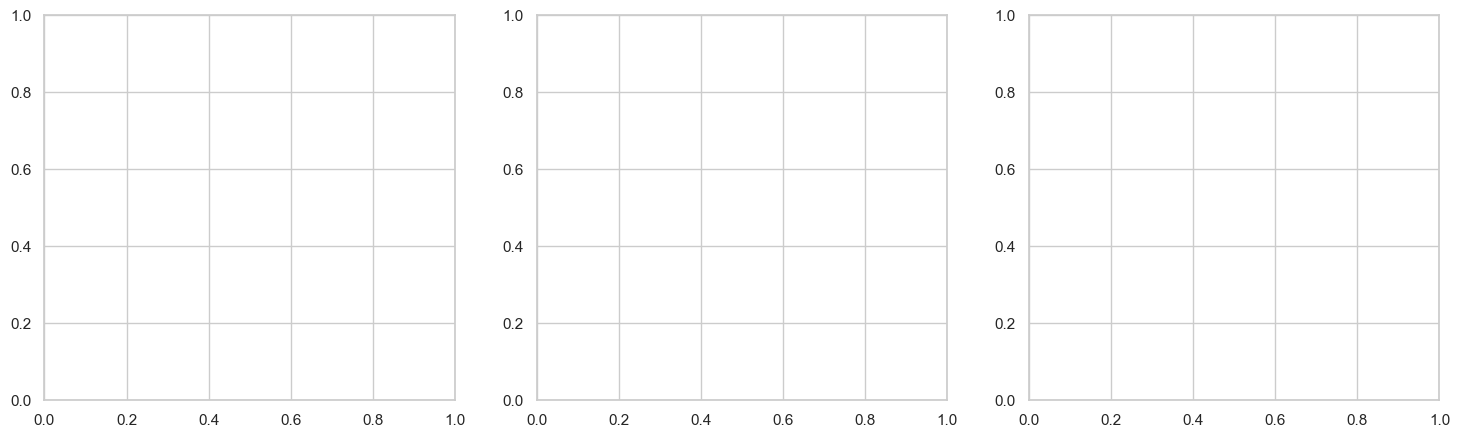

In [102]:
fig,axes = plt.subplots(1,3,figsize=(18,5))

sns.boxplot(
    x="teslimat_durumu",
    y="review_score",
    data=df_master,
    palette="Set2",
    ax=axes[0]
)

axes[0].set_title("Teslimat Durumuna Göre Memnuniyet Puanı")
axes[0].set_xlabel("Teslimat Durumu")
axes[0].set_ylabel("Review Score (1-5)")

top_5 = df_master["product_category_name"].value_counts().head(5).index
df_top5 = df_master[df_master["product_category_name"].isin(top_5)]

sns.barplot(
    x="price",
    y="product_category_name",
    data=df_top5,
    estimator=np.mean,
    ci=None,
    palette="Blues_r",
    ax=axes[1]
)
axes[1].set_title('Popüler 5 Kategoride Ortalama Ürün Fiyatı')
axes[1].set_xlabel('Ortalama Fiyat (BRL)')
axes[1].set_ylabel('Ürün Kategorisi')

sub_df = df_master[df_master['payment_type'].isin(['credit_card', 'boleto', 'voucher', 'debit_card'])]
sns.countplot(
    x='payment_type', 
    hue='yuksek_memnuniyet', 
    data=sub_df, 
    palette='viridis', 
    ax=axes[2]
)
axes[2].set_title('Ödeme Yöntemine Göre Memnuniyet Dağılımı')
axes[2].set_xlabel('Ödeme Yöntemi')
axes[2].set_ylabel('Sipariş Sayısı')
axes[2].legend(title='Yüksek Puan (>=4)', labels=['Hayır', 'Evet'])

plt.tight_layout()
plt.show()

ValueError: Could not interpret value `teslimat_durumu` for `x`. An entry with this name does not appear in `data`.

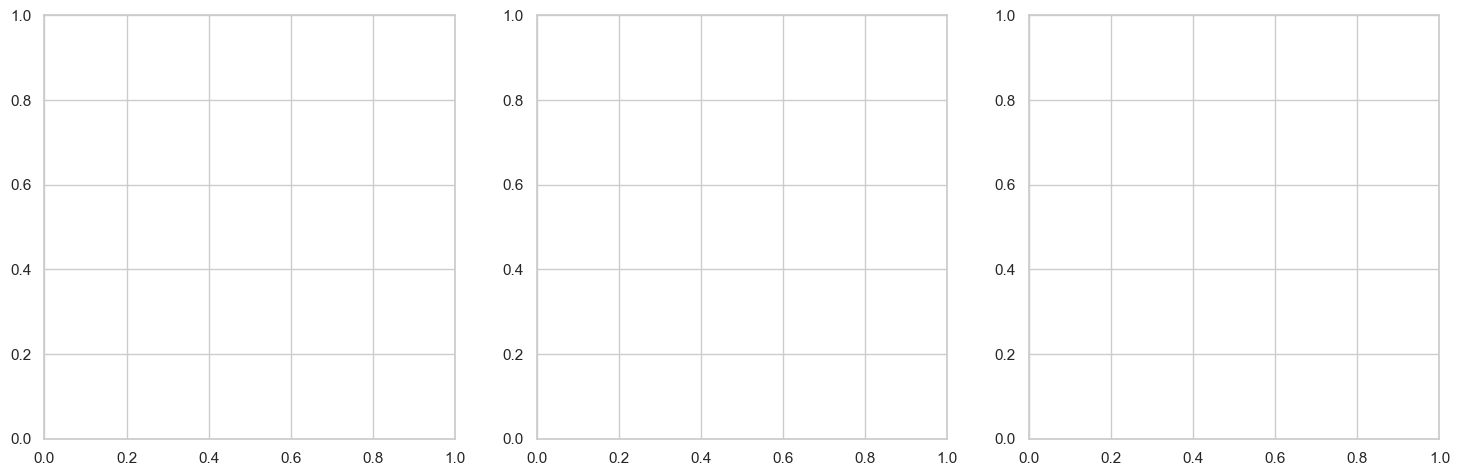

In [104]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Grafik teması ve genel boyut ayarları
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# ----------------------------------------------------
# 1. GRAFİK: t-Testi Görseli (Teslimat Durumu vs. Memnuniyet)
# ----------------------------------------------------
sns.boxplot(
    x='teslimat_durumu', 
    y='review_score', 
    data=df_master, 
    palette=['#2ecc71', '#e74c3c'], 
    ax=axes[0]
)
axes[0].set_title('1. t-Testi: Teslimat Durumu vs. Memnuniyet\n(p < 0.05 | Anlamlı Fark Var)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Teslimat Durumu')
axes[0].set_ylabel('Müşteri Puanı (1-5)')

# ----------------------------------------------------
# 2. GRAFİK: ANOVA Görseli (Kategori vs. Ortalama Fiyat)
# ----------------------------------------------------
# En çok satan ilk 5 kategoriyi filtreleyelim
top_5_cats = df_master['product_category_name'].value_counts().head(5).index
df_top5 = df_master[df_master['product_category_name'].isin(top_5_cats)]

sns.barplot(
    x='price', 
    y='product_category_name', 
    data=df_top5, 
    estimator=np.mean, 
    errorbar=None, 
    palette='Blues_r', 
    ax=axes[1]
)
axes[1].set_title('2. ANOVA: Kategorilere Göre Ortalama Fiyat\n(p < 0.05 | Kategoriler Arası Fark Var)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Ortalama Fiyat (BRL)')
axes[1].set_ylabel('Ürün Kategorisi')

# ----------------------------------------------------
# 3. GRAFİK: Ki-Kare Görseli (Ödeme Yöntemi vs. Memnuniyet Oranı)
# ----------------------------------------------------
# Temel ödeme yöntemlerini filtreleyelim
sub_df = df_master[df_master['payment_type'].isin(['credit_card', 'boleto', 'voucher', 'debit_card'])].copy()

sns.countplot(
    x='payment_type', 
    hue='yuksek_memnuniyet', 
    data=sub_df, 
    palette=['#95a5a6', '#3498db'], 
    ax=axes[2]
)
axes[2].set_title('3. Ki-Kare: Ödeme Yöntemi vs. Memnuniyet\n(p < 0.05 | Değişkenler Bağımlı)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Ödeme Yöntemi')
axes[2].set_ylabel('Sipariş Adedi')
axes[2].legend(title='Yüksek Puan (>=4)', labels=['Düşük (1-3)', 'Yüksek (4-5)'])

# Yerleşim düzenleme ve kaydetme
plt.tight_layout()
plt.savefig('slayt_3_hipotez_testleri.png', dpi=300) # Görseli bilgisayarına yüksek kalitede kaydeder
plt.show()

In [103]:
order.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [53]:
payment.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [54]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [55]:
dataset.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [56]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [57]:
sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [58]:
customers.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_zip_code_prefix,99441.0,35137.474583,29797.938996,1003.0,11347.0,24416.0,58900.0,99990.0


In [59]:
order.describe().T

,count,mean,std,min,25%,50%,75%,max
order_item_id,112650.0,1.197834,0.705124,1.00,1.00,1.00,1.00,21.00
price,112650.0,120.653739,183.633928,0.85,39.90,74.99,134.90,6735.00
freight_value,112650.0,19.990320,15.806405,0.00,13.08,16.26,21.15,409.68


In [60]:
payment.describe().T

,count,mean,std,min,25%,50%,75%,max
payment_sequential,103886.0,1.092679,0.706584,1.0,1.00,1.0,1.0000,29.00
payment_installments,103886.0,2.853349,2.687051,0.0,1.00,1.0,4.0000,24.00
payment_value,103886.0,154.100380,217.494064,0.0,56.79,100.0,171.8375,13664.08


In [61]:
reviews.describe().T

,count,mean,std,min,25%,50%,75%,max
review_score,99224.0,4.086421,1.347579,1.0,4.0,5.0,5.0,5.0


In [62]:
dataset.describe().T

,count,unique,top,freq
order_id,99441,99441,e481f51cbdc54678b7cc49136f2d6af7,1
customer_id,99441,99441,9ef432eb6251297304e76186b10a928d,1
order_status,99441,8,delivered,96478
order_purchase_timestamp,99441,98875,2018-04-11 10:48:14,3
order_approved_at,99281,90733,2018-02-27 04:31:10,9
order_delivered_carrier_date,97658,81018,2018-05-09 15:48:00,47
order_delivered_customer_date,96476,95664,2018-05-08 23:38:46,3
order_estimated_delivery_date,99441,459,2017-12-20 00:00:00,522


In [63]:
products.describe().T

,count,mean,std,min,25%,50%,75%,max
product_name_lenght,32341.0,48.476949,10.245741,5.0,42.0,51.0,57.0,76.0
product_description_lenght,32341.0,771.495285,635.115225,4.0,339.0,595.0,972.0,3992.0
product_photos_qty,32341.0,2.188986,1.736766,1.0,1.0,1.0,3.0,20.0
product_weight_g,32949.0,2276.472488,4282.038731,0.0,300.0,700.0,1900.0,40425.0
product_length_cm,32949.0,30.815078,16.914458,7.0,18.0,25.0,38.0,105.0
product_height_cm,32949.0,16.937661,13.637554,2.0,8.0,13.0,21.0,105.0
product_width_cm,32949.0,23.196728,12.079047,6.0,15.0,20.0,30.0,118.0


In [64]:
sellers.describe().T

,count,mean,std,min,25%,50%,75%,max
seller_zip_code_prefix,3095.0,32291.059451,32713.45383,1001.0,7093.5,14940.0,64552.5,99730.0


In [65]:
sellers.isnull().sum()
(sellers.isnull().sum() / len(sellers)) * 100

seller_id                 0.0
seller_zip_code_prefix    0.0
seller_city               0.0
seller_state              0.0
dtype: float64

In [66]:
sellers.duplicated().sum()

np.int64(0)

In [67]:
sellers.corr(numeric_only=True)

,seller_zip_code_prefix
seller_zip_code_prefix,1.0


In [68]:
products.isnull().sum()
(products.isnull().sum() / len(products)) * 100

product_id                    0.000000
product_category_name         1.851234
product_name_lenght           1.851234
product_description_lenght    1.851234
product_photos_qty            1.851234
product_weight_g              0.006070
product_length_cm             0.006070
product_height_cm             0.006070
product_width_cm              0.006070
dtype: float64

In [69]:
products.duplicated().sum()

np.int64(0)

In [70]:
products.corr(numeric_only=True)

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
product_name_lenght,1.000000,0.098741,0.134321,0.044664,0.080556,-0.016494,0.070741
product_description_lenght,0.098741,1.000000,0.108745,0.062445,0.034849,0.063519,-0.030869
product_photos_qty,0.134321,0.108745,1.000000,0.036539,0.067447,0.004000,0.026319
product_weight_g,0.044664,0.062445,0.036539,1.000000,0.476813,0.563910,0.527597
product_length_cm,0.080556,0.034849,0.067447,0.476813,1.000000,0.204889,0.542409
product_height_cm,-0.016494,0.063519,0.004000,0.563910,0.204889,1.000000,0.313491
product_width_cm,0.070741,-0.030869,0.026319,0.527597,0.542409,0.313491,1.000000


In [71]:
dataset.isnull().sum()
(dataset.isnull().sum() / len(dataset)) * 100 

order_id                         0.000000
customer_id                      0.000000
order_status                     0.000000
order_purchase_timestamp         0.000000
order_approved_at                0.160899
order_delivered_carrier_date     1.793023
order_delivered_customer_date    2.981668
order_estimated_delivery_date    0.000000
dtype: float64

In [72]:
dataset.duplicated().sum()

np.int64(0)

In [73]:
dataset.corr(numeric_only=True)

""


In [74]:
reviews.isnull().sum()
(reviews.isnull().sum() / len(reviews)) * 100

review_id                   0.000000
order_id                    0.000000
review_score                0.000000
review_comment_title       88.341530
review_comment_message     58.702532
review_creation_date        0.000000
review_answer_timestamp     0.000000
dtype: float64

In [75]:
reviews.duplicated().sum()

np.int64(0)

In [76]:
reviews.corr(numeric_only=True)

,review_score
review_score,1.0


In [77]:
payment.isnull().sum()
(payment.isnull().sum() / len(payment)) * 100

order_id                0.0
payment_sequential      0.0
payment_type            0.0
payment_installments    0.0
payment_value           0.0
dtype: float64

In [78]:
payment.duplicated().sum()

np.int64(0)

In [79]:
payment.corr(numeric_only=True)

,payment_sequential,payment_installments,payment_value
payment_sequential,1.000000,-0.086363,-0.069593
payment_installments,-0.086363,1.000000,0.330811
payment_value,-0.069593,0.330811,1.000000


In [80]:
order.isnull().sum()
(order.isnull().sum() / len(order)) * 100

order_id               0.0
order_item_id          0.0
product_id             0.0
seller_id              0.0
shipping_limit_date    0.0
price                  0.0
freight_value          0.0
dtype: float64

In [81]:
order.duplicated().sum()

np.int64(0)

In [82]:
order.corr(numeric_only=True)

,order_item_id,price,freight_value
order_item_id,1.000000,-0.060522,-0.029380
price,-0.060522,1.000000,0.414204
freight_value,-0.029380,0.414204,1.000000


In [83]:
customers.isnull().sum()
# Eksik değerlerin yüzdesel oranı
(customers.isnull().sum() / len(customers)) * 100

customer_id                 0.0
customer_unique_id          0.0
customer_zip_code_prefix    0.0
customer_city               0.0
customer_state              0.0
dtype: float64

In [84]:
customers.duplicated().sum()

np.int64(0)

In [85]:
customers.corr(numeric_only=True)

,customer_zip_code_prefix
customer_zip_code_prefix,1.0
